# RakForest — เปรียบเทียบ Single-label, Multi-label Candidate และ CRNN + Sigmoid

Notebook นี้นำ Baseline แบบ **single-label** ที่ฝึกไว้แล้วมาใช้ร่วมกับ **multi-label Candidate** และ **CRNN + Sigmoid** (โมเดลที่สามซึ่งต้องฝึกจาก notebook 09) โดยใช้ Validation split และ preprocessing เดียวกัน สร้างภาพ log-Mel spectrogram จากคลิปจริงพร้อมบันทึก PNG สำหรับ Canva

> ไม่ใช้ Test split ในการเลือกโมเดลหรือปรับ threshold; ตัวเลขใน notebook นี้เป็น Validation เท่านั้น คะแนนไม่ควรตีความว่าเทียบกันตรง ๆ เพราะ target และ objective ต่างกัน
>
> Checkpoint Baseline เดิมที่ชื่อ `rakforest_audio_cnn_best.pt` ไม่ตรงกับ config เดิม จึงใช้ checkpoint ที่ฝึกแยกไว้ `rakforest_audio_cnn_singlelabel_retrained_best.pt`; notebook นี้ reuse checkpoint ดังกล่าวเป็นค่าเริ่มต้น และฝึกใหม่ได้เมื่อเปิด flag ใน cell 4


In [ ]:
from pathlib import Path
import json, random, time, hashlib
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import Audio, display, Markdown
from sklearn.metrics import f1_score, accuracy_score, hamming_loss
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

# รองรับการเปิด notebook จากทั้ง project root และโฟลเดอร์ notebooks
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'data' / 'processed' / 'processed_manifest.parquet').exists():
    candidates = [p for p in Path.home().rglob('RakForest---AI-Powered-Abnormal-Forest-Sound-Detection') if p.is_dir()]
    if not candidates:
        raise FileNotFoundError('หา project root ไม่เจอ กรุณาเปิด notebook จากโฟลเดอร์โปรเจกต์')
    PROJECT_ROOT = candidates[0]

MANIFEST_PATH = PROJECT_ROOT / 'data/processed/processed_manifest.parquet'
MODEL_DIR = PROJECT_ROOT / 'models'
REPORT_DIR = PROJECT_ROOT / 'reports'
ASSET_DIR = REPORT_DIR / 'presentation_assets'
for folder in (MODEL_DIR, REPORT_DIR, ASSET_DIR): folder.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
HAS_MPS = hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else ('mps' if HAS_MPS else 'cpu'))
print('Project:', PROJECT_ROOT)
print('Device:', DEVICE)

SAMPLE_RATE, DURATION_SECONDS = 16000, 4.0
NUM_SAMPLES = int(SAMPLE_RATE * DURATION_SECONDS)
N_MELS, N_FFT, HOP_LENGTH = 64, 1024, 320
BATCH_SIZE, MAX_EPOCHS, PATIENCE = 32, 20, 4
LEARNING_RATE, WEIGHT_DECAY, THRESHOLD = 1e-3, 1e-4, 0.5
NUM_WORKERS = 0
# Requires fresh 10-class checkpoints from the updated training notebooks.
CLASS_NAMES = ['fire','chainsaw','vehicle','human_activity','threat_tactical','gunshot','weather','natural_ambient','silence','other']
CACHE_DIR = PROJECT_ROOT / 'data/processed/logmel_cache_v1'
CACHE_DIR.mkdir(parents=True, exist_ok=True)


Project: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection
Device: mps


## 1. โหลด Manifest และตรวจ split

ใช้ `target_label` สำหรับ Baseline และ `target_labels` สำหรับ Candidate โดยไม่แตะ Test split

In [ ]:
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f'{MANIFEST_PATH} ไม่มีอยู่ — รัน 02_eda_cleaning.ipynb ก่อน')
df = pd.read_parquet(MANIFEST_PATH).copy()
required = {'processed_file','target_label','target_labels','split','group_key','dataset'}
missing = required - set(df.columns)
if missing: raise ValueError(f'Manifest ขาด columns: {sorted(missing)}')
if set(df.split.unique()) != {'train','val','test'}:
    raise ValueError(f'ต้องมี train/val/test splits; พบ {sorted(df.split.unique())}')

def parse_labels(value):
    labels = json.loads(value) if isinstance(value, str) else list(value)
    return list(dict.fromkeys(str(x) for x in labels))

df['target_labels_list'] = df.target_labels.map(parse_labels)
# Manifest เก็บ absolute paths จากตำแหน่งโปรเจกต์เก่า; ย้ายไปชี้ไฟล์คลิปใน workspace ปัจจุบันด้วย basename

def resolve_audio_path(value):
    original = Path(str(value))
    if original.is_file(): return str(original)
    relocated = PROJECT_ROOT / 'data/processed/clips' / original.name
    if relocated.is_file(): return str(relocated)
    raise FileNotFoundError(f'หาไฟล์เสียงไม่พบ: {value} (ลองแล้ว: {relocated})')

df['processed_file'] = df.processed_file.map(resolve_audio_path)
unknown = {label for labels in df.target_labels_list for label in labels} - set(CLASS_NAMES)
if unknown: raise ValueError(f'พบคลาสที่ไม่อยู่ใน CLASS_NAMES: {sorted(unknown)}')
if not set(df.target_label).issubset(CLASS_NAMES): raise ValueError('target_label มีคลาสที่ไม่รู้จัก')
leaks = df.groupby('group_key').split.nunique()
if (leaks > 1).any(): raise ValueError('พบ group_key ที่ข้าม split; ตรวจการแบ่งข้อมูลก่อนฝึก')
train_df = df[df.split.eq('train')].reset_index(drop=True)
val_df = df[df.split.eq('val')].reset_index(drop=True)
print(f'Train: {len(train_df):,} | Validation: {len(val_df):,} | Test (ไม่ใช้ใน notebook นี้): {int(df.split.eq("test").sum()):,}')
print('Validation examples with >1 verified labels:', sum(len(v)>1 for v in val_df.target_labels_list))
display(pd.crosstab(df.split, df.target_label).reindex(columns=CLASS_NAMES, fill_value=0))


Train: 112,245 | Validation: 24,365 | Test (ไม่ใช้ใน notebook นี้): 24,054
Validation examples with >1 verified labels: 0


target_label,fire,chainsaw,vehicle,human_activity,threat_tactical,gunshot,weather,natural_ambient,silence,other
split,,,,,,,,,,
test,304,3220,3313,6640,134,2638,225,4615,24,2941
train,1530,15045,15827,30967,642,12564,994,21460,104,13112
val,307,3234,3479,6708,134,2679,214,4597,22,2991


## 2. สร้างภาพ log-Mel spectrogram จากเสียงจริง

ภาพใช้ไฟล์เสียงใน Validation และบันทึกไว้ใน `reports/presentation_assets/` เพื่อนำไปใส่ Canva ได้

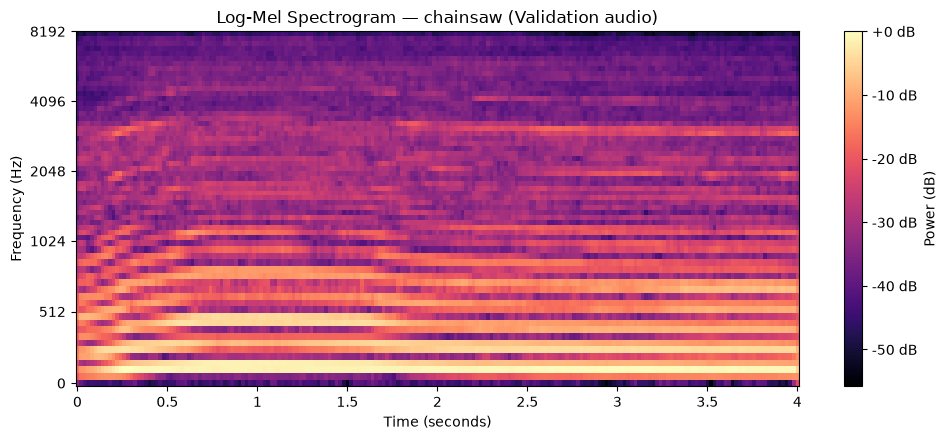

Saved image: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/presentation_assets/rakforest_validation_log_mel.png


In [ ]:
def load_wave(path):
    y, sr = sf.read(str(path), dtype='float32', always_2d=False)
    if y.ndim == 2: y = y.mean(axis=1)
    y = np.asarray(y, dtype=np.float32)
    if sr != SAMPLE_RATE: y = librosa.resample(y, orig_sr=sr, target_sr=SAMPLE_RATE)
    y -= float(y.mean())
    if len(y) < NUM_SAMPLES: y = np.pad(y, (0, NUM_SAMPLES-len(y)))
    else: y = y[:NUM_SAMPLES]
    return y.astype(np.float32)

def to_logmel(y):
    mel = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_fft=N_FFT,
        hop_length=HOP_LENGTH, n_mels=N_MELS, power=2.0)
    logmel_db = librosa.power_to_db(mel, ref=np.max)
    normalized = (logmel_db-logmel_db.mean())/(logmel_db.std()+1e-6)
    return normalized.astype(np.float32), logmel_db

# เลือกคลิปที่มี label หลักชัดเจนและมีไฟล์จริง
sample_pool = val_df[~val_df.dataset.eq('zenodo_fire')]
preferred = sample_pool[(sample_pool.dataset.eq('esc50')) & (sample_pool.target_label.eq('chainsaw'))]
if preferred.empty: preferred = sample_pool[(sample_pool.dataset.eq('rfcx_frugalai')) & (sample_pool.target_label.eq('chainsaw'))]
sample_row = preferred.iloc[0] if len(preferred) else sample_pool.iloc[0]
y_audio = load_wave(sample_row.processed_file)
logmel_norm, logmel_db = to_logmel(y_audio)
fig, ax = plt.subplots(figsize=(10, 4.5))
img = librosa.display.specshow(logmel_db, sr=SAMPLE_RATE, hop_length=HOP_LENGTH,
    x_axis='time', y_axis='mel', cmap='magma', ax=ax)
ax.set_title(f"Log-Mel Spectrogram — {sample_row.target_label} (Validation audio)")
ax.set_xlabel('Time (seconds)'); ax.set_ylabel('Frequency (Hz)')
fig.colorbar(img, ax=ax, format='%+2.0f dB', label='Power (dB)')
fig.tight_layout()
mel_image_path = ASSET_DIR / 'rakforest_validation_log_mel.png'
fig.savefig(mel_image_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved image:', mel_image_path)
display(Audio(y_audio, rate=SAMPLE_RATE))


## 3. Dataset และ CNN สำหรับ Single-label Baseline

Baseline ทำนายคลาสเดียวด้วย Softmax/Cross-Entropy; Candidate ใช้ CNN 4 blocks (16–128 channels) และ CRNN ใช้ 4 blocks (CNN + bidirectional GRU (hidden size 64)); ทั้งคู่ทำนายคะแนนอิสระรายคลาสด้วย Sigmoid/BCE

In [ ]:
def cache_path(audio_path):
    p = Path(audio_path); stat = p.stat()
    key = f'{p.resolve()}|{stat.st_size}|{stat.st_mtime_ns}|{SAMPLE_RATE}|{N_MELS}|{N_FFT}|{HOP_LENGTH}'
    return CACHE_DIR / (hashlib.sha1(key.encode()).hexdigest()+'.npy')

def spec_augment(x):
    x = x.clone(); _, n_mels, n_frames = x.shape
    if random.random() < .5:
        width = random.randint(1, max(1, n_mels//8)); start = random.randint(0, max(0,n_mels-width)); x[:,start:start+width,:] = 0
    if random.random() < .5:
        width = random.randint(1, max(1,n_frames//10)); start = random.randint(0, max(0,n_frames-width)); x[:,:,start:start+width] = 0
    return x

class RakForestDataset(Dataset):
    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True); self.training = training
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        cp = cache_path(row.processed_file)
        if cp.exists(): x = np.load(cp).astype(np.float32)
        else:
            x, _ = to_logmel(load_wave(row.processed_file))
            tmp = cp.with_name(cp.stem+'.tmp.npy'); np.save(tmp, x.astype(np.float16)); tmp.replace(cp)
        x = torch.from_numpy(x).unsqueeze(0)
        if self.training: x = spec_augment(x)
        single_y = CLASS_NAMES.index(row.target_label)
        multi_y = np.zeros(len(CLASS_NAMES), dtype=np.float32)
        for label in row.target_labels_list: multi_y[CLASS_NAMES.index(label)] = 1.0
        return x, torch.tensor(single_y, dtype=torch.long), torch.from_numpy(multi_y)

train_ds = RakForestDataset(train_df, training=True)
val_ds = RakForestDataset(val_df, training=False)
pin = DEVICE.type == 'cuda'
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True), nn.MaxPool2d(2))
    def forward(self, x): return self.block(x)

class AudioCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(ConvBlock(1,16),ConvBlock(16,32),ConvBlock(32,64),
            ConvBlock(64,128),nn.AdaptiveAvgPool2d((1,1)))
        self.classifier = nn.Sequential(nn.Flatten(),nn.Dropout(.35),nn.Linear(128,num_classes))
    def forward(self, x): return self.classifier(self.features(x))

xb, y_single_b, y_multi_b = next(iter(val_loader))
print('Input shape:', tuple(xb.shape), '| single target:', tuple(y_single_b.shape), '| multi target:', tuple(y_multi_b.shape))


class CRNNConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__(); self.block=nn.Sequential(nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False),nn.BatchNorm2d(out_channels),nn.ReLU(inplace=True),nn.MaxPool2d(2))
    def forward(self,x): return self.block(x)

class CRNN(nn.Module):
    """CNN extracts frame features; bidirectional GRU models their temporal order."""
    def __init__(self,num_classes):
        super().__init__()
        self.features=nn.Sequential(CRNNConvBlock(1,16),CRNNConvBlock(16,32),CRNNConvBlock(32,64),CRNNConvBlock(64,128))
        self.gru=nn.GRU(input_size=128,hidden_size=64,num_layers=1,batch_first=True,bidirectional=True)
        self.dropout=nn.Dropout(.35)
        self.classifier=nn.Linear(128,num_classes)
    def forward(self,x):
        z=self.features(x)              # [batch, channels, mel_bins, time_steps]
        z=z.mean(dim=2).transpose(1,2)  # [batch, time_steps, channels]
        sequence,_=self.gru(z)
        pooled=sequence.mean(dim=1)
        return self.classifier(self.dropout(pooled))



Input shape: (32, 1, 64, 201) | single target: (32,) | multi target: (32, 10)


## 4. โหลดหรือฝึก Single-label Baseline

เพิ่มคลาส gunshot ทำให้ checkpoint Single-label เดิมใช้ไม่ได้ ต้องฝึกใหม่จาก manifest 10 คลาส; ใช้ Train ฝึกและ Validation เลือก Epoch

In [20]:
single_model = AudioCNN(len(CLASS_NAMES)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(single_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=.5, patience=2)

@torch.no_grad()
def eval_single(loader):
    single_model.eval(); ys=[]; ps=[]; total_loss=0.0
    for xb, yb, _ in tqdm(loader, leave=False, desc='Validation'):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = single_model(xb); total_loss += criterion(logits,yb).item()*len(yb)
        ys.append(yb.cpu().numpy()); ps.append(torch.softmax(logits,dim=1).cpu().numpy())
    y = np.concatenate(ys); p = np.concatenate(ps); pred = p.argmax(axis=1)
    return total_loss/max(len(loader.dataset),1), y, p, pred, float(f1_score(y,pred,average='macro',zero_division=0))

single_checkpoint_path=MODEL_DIR/'rakforest_audio_cnn_singlelabel_retrained_best.pt'
history_path=REPORT_DIR/'singlelabel_retrained_training_history.csv'
RETRAIN_SINGLE_BASELINE=True  # class set changed to 10 classes; retrain the stale baseline
if RETRAIN_SINGLE_BASELINE or not single_checkpoint_path.exists() or not history_path.exists():
    history=[]; best_f1=-1.; best_epoch=0; stale=0
    for epoch in range(1, MAX_EPOCHS+1):
        start=time.time(); single_model.train(); total=0.0; seen=0; train_true_batches=[]; train_pred_batches=[]
        for xb, yb, _ in tqdm(train_loader, leave=False, desc=f'Train {epoch}/{MAX_EPOCHS}'):
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True); logits=single_model(xb); loss=criterion(logits,yb)
            train_true_batches.append(yb.detach().cpu().numpy())
            train_pred_batches.append(logits.detach().argmax(dim=1).cpu().numpy())
            loss.backward(); torch.nn.utils.clip_grad_norm_(single_model.parameters(),5.0); optimizer.step()
            total += loss.item()*len(yb); seen += len(yb)
        train_loss=total/max(seen,1)
        train_macro_f1=float(f1_score(np.concatenate(train_true_batches),np.concatenate(train_pred_batches),average='macro',zero_division=0))
        val_loss,y_val_single,p_val_single,pred_val_single,val_macro_f1=eval_single(val_loader)
        scheduler.step(val_macro_f1)
        history.append({'epoch':epoch,'train_loss':train_loss,'train_macro_f1':train_macro_f1,'val_loss':val_loss,'val_macro_f1':val_macro_f1,'seconds':time.time()-start})
        print(f'Epoch {epoch:02d}/{MAX_EPOCHS} | train loss {train_loss:.4f}, train Macro-F1 {train_macro_f1:.4f} | val loss {val_loss:.4f}, val Macro-F1 {val_macro_f1:.4f}')
        if val_macro_f1 > best_f1:
            best_f1=val_macro_f1; best_epoch=epoch; stale=0
            torch.save({'model_type':'singlelabel_audio_cnn','model_state_dict':single_model.state_dict(),
                'class_names':CLASS_NAMES,'best_epoch':best_epoch,'best_val_macro_f1':best_f1,
                'config':{'sample_rate':SAMPLE_RATE,'duration_seconds':DURATION_SECONDS,'n_mels':N_MELS,'n_fft':N_FFT,'hop_length':HOP_LENGTH,'architecture':'AudioCNN-v1','output_activation':'softmax'},
                'manifest':'data/processed/processed_manifest.parquet','training_split':'train','selection_split':'val'},single_checkpoint_path)
        else:
            stale += 1
            if stale >= PATIENCE: print('Early stopping.'); break

    history_df=pd.DataFrame(history)
    history_path=REPORT_DIR/'singlelabel_retrained_training_history.csv'
    history_df.to_csv(history_path,index=False)
    print('Best epoch:',best_epoch,'| Validation Macro-F1:',round(best_f1,4))
    print('Saved checkpoint:',single_checkpoint_path)
else:
    single_ckpt_cached=torch.load(single_checkpoint_path,map_location=DEVICE,weights_only=True)
    if single_ckpt_cached.get('model_type')!='singlelabel_audio_cnn' or single_ckpt_cached.get('class_names')!=CLASS_NAMES:
        raise ValueError('Single-label checkpoint incompatible; set RETRAIN_SINGLE_BASELINE=True')
    cfg=single_ckpt_cached.get('config',{})
    for key,value in {'sample_rate':SAMPLE_RATE,'duration_seconds':DURATION_SECONDS,'n_mels':N_MELS,'n_fft':N_FFT,'hop_length':HOP_LENGTH}.items():
        if cfg.get(key)!=value: raise ValueError(f'Single-label checkpoint feature config mismatch: {key}')
    single_model.load_state_dict(single_ckpt_cached['model_state_dict']); single_model.eval()
    history_df=pd.read_csv(history_path)
    best_epoch=int(single_ckpt_cached.get('best_epoch',0)); best_f1=float(single_ckpt_cached.get('best_val_macro_f1',float('nan')))
    print('Reused trained Single-label checkpoint; no training run.')
    print('Best epoch:',best_epoch,'| Validation Macro-F1:',round(best_f1,4))
    print('Training history:',history_path)


Train 1/20:   0%|          | 0/3508 [00:00<?, ?it/s]

Validation:   0%|          | 0/762 [00:00<?, ?it/s]

Epoch 01/20 | train loss 0.5088, train Macro-F1 0.5619 | val loss 0.3838, val Macro-F1 0.6149


Train 2/20:   0%|          | 0/3508 [00:00<?, ?it/s]

Validation:   0%|          | 0/762 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.3853, train Macro-F1 0.6289 | val loss 0.3220, val Macro-F1 0.6548


... (50 outputs left out)

Epoch 19/20 | train loss 0.1943, train Macro-F1 0.7867 | val loss 0.1961, val Macro-F1 0.8020


Train 20/20:   0%|          | 0/3508 [00:00<?, ?it/s]

Validation:   0%|          | 0/762 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.1926, train Macro-F1 0.7965 | val loss 0.2076, val Macro-F1 0.7976
Best epoch: 18 | Validation Macro-F1: 0.8127
Saved checkpoint: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/models/rakforest_audio_cnn_singlelabel_retrained_best.pt


## 5. Candidate Models — ประเมิน Multi-label Candidate

โหลด Candidate checkpoint เดิมและคำนวณผลบน Validation ชุดเดียวกัน ใช้ threshold 0.5 ที่บันทึกไว้ ไม่ค้นหา threshold จาก Validation ในขั้นนี้

In [ ]:
candidate_path = MODEL_DIR/'rakforest_audio_cnn_multilabel_best.pt'
if not candidate_path.exists(): raise FileNotFoundError(f'{candidate_path} ไม่มีอยู่ — รัน 03_train_model.ipynb ก่อน')
candidate_ckpt = torch.load(candidate_path, map_location=DEVICE, weights_only=True)
if candidate_ckpt.get('schema_version') != 'multilabel-v1': raise ValueError('Candidate checkpoint ไม่ใช่ multilabel-v1')
if candidate_ckpt.get('class_names') != CLASS_NAMES: raise ValueError('ลำดับคลาสของ Candidate ไม่ตรงกับ notebook')
candidate_model = AudioCNN(len(CLASS_NAMES)).to(DEVICE)
candidate_model.load_state_dict(candidate_ckpt['model_state_dict']); candidate_model.eval()

crnn_path=MODEL_DIR/'rakforest_crnn_sigmoid_best.pt'
if not crnn_path.exists(): raise FileNotFoundError(f'{crnn_path} ไม่มีอยู่ — รัน 09_train_crnn_sigmoid.ipynb ก่อน')
crnn_ckpt=torch.load(crnn_path,map_location=DEVICE,weights_only=True)
if crnn_ckpt.get('schema_version')!='crnn-sigmoid-v1' or crnn_ckpt.get('class_names')!=CLASS_NAMES: raise ValueError('CRNN checkpoint schema/class order ไม่ตรง')
crnn_model=CRNN(len(CLASS_NAMES)).to(DEVICE)
crnn_model.load_state_dict(crnn_ckpt['model_state_dict']); crnn_model.eval()

single_ckpt = torch.load(single_checkpoint_path, map_location=DEVICE, weights_only=True)
single_model.load_state_dict(single_ckpt['model_state_dict']); single_model.eval()
all_single_true=[]; all_single_prob=[]; all_multi_true=[]; all_multi_prob=[]; all_crnn_prob=[]
with torch.no_grad():
    for xb, y_single, y_multi in tqdm(val_loader, desc='Compare models on validation'):
        xb=xb.to(DEVICE)
        single_prob=torch.softmax(single_model(xb),dim=1).cpu().numpy()
        multi_prob=torch.sigmoid(candidate_model(xb)).cpu().numpy()
        crnn_prob=torch.sigmoid(crnn_model(xb)).cpu().numpy()
        all_single_true.append(y_single.numpy()); all_single_prob.append(single_prob)
        all_multi_true.append(y_multi.numpy()); all_multi_prob.append(multi_prob); all_crnn_prob.append(crnn_prob)
y_single_true=np.concatenate(all_single_true); single_prob=np.concatenate(all_single_prob)
y_multi_true=np.concatenate(all_multi_true); multi_prob=np.concatenate(all_multi_prob); crnn_prob=np.concatenate(all_crnn_prob)
single_pred=single_prob.argmax(axis=1)
multi_pred=(multi_prob>=THRESHOLD).astype(np.int32)
crnn_pred=(crnn_prob>=THRESHOLD).astype(np.int32)

single_metrics={
    'validation_macro_f1':float(f1_score(y_single_true,single_pred,average='macro',zero_division=0)),
    'validation_accuracy':float(accuracy_score(y_single_true,single_pred)),
    'validation_exact_match':float(np.mean(np.all(np.eye(len(CLASS_NAMES),dtype=int)[y_single_true]==np.eye(len(CLASS_NAMES),dtype=int)[single_pred],axis=1))),
}
multi_metrics={
    'validation_macro_f1':float(f1_score(y_multi_true,multi_pred,average='macro',zero_division=0)),
    'validation_micro_f1':float(f1_score(y_multi_true,multi_pred,average='micro',zero_division=0)),
    'validation_exact_match':float(np.mean(np.all(y_multi_true==multi_pred,axis=1))),
    'validation_hamming_loss':float(hamming_loss(y_multi_true,multi_pred)),
    'threshold':THRESHOLD,
}
print('Single-label Baseline:',single_metrics)
crnn_metrics={
    'validation_macro_f1':float(f1_score(y_multi_true,crnn_pred,average='macro',zero_division=0)),
    'validation_micro_f1':float(f1_score(y_multi_true,crnn_pred,average='micro',zero_division=0)),
    'validation_exact_match':float(np.mean(np.all(y_multi_true==crnn_pred,axis=1))),
    'validation_hamming_loss':float(hamming_loss(y_multi_true,crnn_pred)),
    'threshold':THRESHOLD,
}
print('Multi-label Candidate:',multi_metrics)
print('CRNN + Sigmoid:',crnn_metrics)


Compare models on validation:   0%|          | 0/762 [00:00<?, ?it/s]

Single-label Baseline: {'validation_macro_f1': 0.8127256824927217, 'validation_accuracy': 0.934290991175867, 'validation_exact_match': 0.934290991175867}
Multi-label Candidate: {'validation_macro_f1': 0.7513443953670111, 'validation_micro_f1': 0.8966253982182713, 'validation_exact_match': 0.8414529037553868, 'validation_hamming_loss': 0.02224091935152883, 'threshold': 0.5}
CRNN + Sigmoid: {'validation_macro_f1': 0.657424608676417, 'validation_micro_f1': 0.7381004208387753, 'validation_exact_match': 0.6510158013544018, 'validation_hamming_loss': 0.05925713113072029, 'threshold': 0.5}


## 6. Validation report แยกรายคลาส

ตารางนี้คำนวณบน Validation เดียวกัน โดย Single ใช้คำตอบคลาสเดียว และ Candidate ใช้ threshold 0.5 กับ target แบบ multi-hot รายงานแยกตามงานเพื่อให้เห็นคลาสที่ทำได้/พลาด ไม่ใช้ Test เลือกโมเดล


Validation Macro-F1: 0.8127 | Micro-F1: 0.9343 | Exact match: 0.9343 | Hamming loss: 0.0131
                 precision    recall  f1-score   support

           fire      0.960     0.860     0.907       307
       chainsaw      0.949     0.921     0.935      3234
        vehicle      0.911     0.938     0.924      3479
 human_activity      0.953     0.974     0.963      6708
threat_tactical      0.513     0.440     0.474       134
        gunshot      0.962     0.988     0.975      2679
        weather      0.686     0.561     0.617       214
natural_ambient      0.942     0.944     0.943      4597
        silence      0.889     0.364     0.516        22
          other      0.892     0.854     0.873      2991

      micro avg      0.934     0.934     0.934     24365
      macro avg      0.866     0.784     0.813     24365
   weighted avg      0.933     0.934     0.933     24365
    samples avg      0.934     0.934     0.934     24365

Saved report: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/Ra

,class,support,single_precision,single_recall,single_f1,candidate_precision,candidate_recall,candidate_f1,crnn_precision,crnn_recall,crnn_f1
0,fire,307,0.9600,0.8599,0.9072,0.6940,0.9381,0.7978,0.7613,0.9870,0.8596
1,chainsaw,3234,0.9490,0.9215,0.9350,0.8442,0.9635,0.8999,0.8630,0.9722,0.9144
2,vehicle,3479,0.9112,0.9379,0.9244,0.8033,0.9707,0.8791,0.8357,0.9750,0.9000
3,human_activity,6708,0.9534,0.9736,0.9634,0.9063,0.9833,0.9432,0.6721,0.7388,0.7039
4,threat_tactical,134,0.5130,0.4403,0.4739,0.3068,0.6045,0.4070,0.0987,0.9104,0.1781
5,gunshot,2679,0.9619,0.9884,0.9750,0.9394,0.9895,0.9638,0.9257,0.3162,0.4713
6,weather,214,0.6857,0.5607,0.6170,0.3326,0.7523,0.4613,0.3002,0.9159,0.4521
7,natural_ambient,4597,0.9418,0.9437,0.9427,0.8780,0.9624,0.9182,0.8806,0.9689,0.9226
8,silence,22,0.8889,0.3636,0.5161,0.3667,0.5000,0.4231,0.4400,1.0000,0.6111
9,other,2991,0.8923,0.8536,0.8725,0.7302,0.9348,0.8199,0.3943,0.9726,0.5611


CRNN validation classification report:
                 precision    recall  f1-score   support

           fire      0.761     0.987     0.860       307
       chainsaw      0.863     0.972     0.914      3234
        vehicle      0.836     0.975     0.900      3479
 human_activity      0.672     0.739     0.704      6708
threat_tactical      0.099     0.910     0.178       134
        gunshot      0.926     0.316     0.471      2679
        weather      0.300     0.916     0.452       214
natural_ambient      0.881     0.969     0.923      4597
        silence      0.440     1.000     0.611        22
          other      0.394     0.973     0.561      2991

      micro avg      0.661     0.835     0.738     24365
      macro avg      0.617     0.876     0.657     24365
   weighted avg      0.748     0.835     0.755     24365
    samples avg      0.738     0.835     0.768     24365

Saved: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports

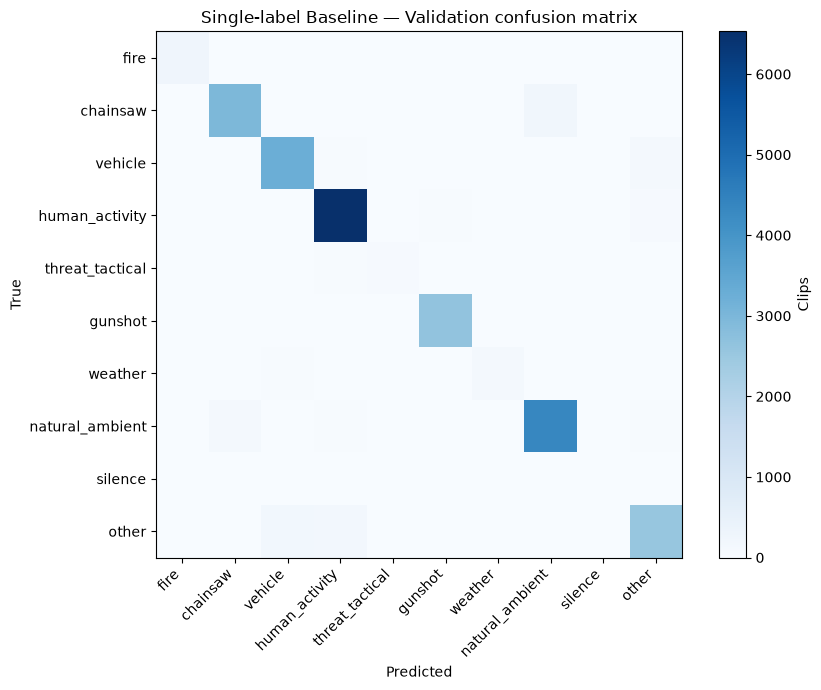

Saved: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/single_multi_crnn_validation_by_class.csv /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/singlelabel_validation_confusion_matrix.csv /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/presentation_assets/rakforest_singlelabel_validation_confusion_matrix.png
Saved CRNN model error analysis: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/crnn_validation_error_analysis_by_class.csv /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/crnn_validation_misclassified_clips.csv


In [ ]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

# Format Single-label predictions as one-hot vectors so the report has the same
# per-class and average rows (micro/macro/weighted/samples) as the Multi-label report.
single_true_onehot=np.eye(len(CLASS_NAMES),dtype=np.int32)[y_single_true]
single_pred_onehot=np.eye(len(CLASS_NAMES),dtype=np.int32)[single_pred]
single_micro_f1=float(f1_score(single_true_onehot,single_pred_onehot,average='micro',zero_division=0))
single_exact_match=float(np.mean(np.all(single_true_onehot==single_pred_onehot,axis=1)))
single_hamming_loss=float(hamming_loss(single_true_onehot,single_pred_onehot))
print(f"Validation Macro-F1: {single_metrics['validation_macro_f1']:.4f} | Micro-F1: {single_micro_f1:.4f} | Exact match: {single_exact_match:.4f} | Hamming loss: {single_hamming_loss:.4f}")
single_report_text=classification_report(single_true_onehot,single_pred_onehot,target_names=CLASS_NAMES,digits=3,zero_division=0)
print(single_report_text)
single_report_path=REPORT_DIR/'singlelabel_validation_classification_report.txt'
single_report_path.write_text(single_report_text,encoding='utf-8')
print('Saved report:',single_report_path)

single_pr, single_rc, single_f1, single_support = precision_recall_fscore_support(
    y_single_true, single_pred, labels=np.arange(len(CLASS_NAMES)), average=None, zero_division=0)
multi_pr, multi_rc, multi_f1, multi_support = precision_recall_fscore_support(
    y_multi_true, multi_pred, average=None, zero_division=0)
crnn_pr, crnn_rc, crnn_f1, crnn_support = precision_recall_fscore_support(
    y_multi_true, crnn_pred, average=None, zero_division=0)
validation_class_report = pd.DataFrame({
    'class':CLASS_NAMES,
    'support':single_support.astype(int),
    'single_precision':single_pr, 'single_recall':single_rc, 'single_f1':single_f1,
    'candidate_precision':multi_pr, 'candidate_recall':multi_rc, 'candidate_f1':multi_f1,
    'crnn_precision':crnn_pr, 'crnn_recall':crnn_rc, 'crnn_f1':crnn_f1,
})
display(validation_class_report.round(4))
class_report_path=REPORT_DIR/'single_multi_crnn_validation_by_class.csv'
validation_class_report.to_csv(class_report_path,index=False)
crnn_class_report_text=classification_report(y_multi_true,crnn_pred,target_names=CLASS_NAMES,digits=3,zero_division=0)
crnn_class_report_path=REPORT_DIR/'crnn_sigmoid_validation_classification_report.txt'
crnn_class_report_path.write_text(crnn_class_report_text,encoding='utf-8')
print('CRNN validation classification report:')
print(crnn_class_report_text)
print('Saved:',crnn_class_report_path)

single_cm=confusion_matrix(y_single_true,single_pred,labels=np.arange(len(CLASS_NAMES)))
cm_path=REPORT_DIR/'singlelabel_validation_confusion_matrix.csv'
pd.DataFrame(single_cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(cm_path)
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(single_cm,cmap='Blues')
ax.set_xticks(np.arange(len(CLASS_NAMES)),CLASS_NAMES,rotation=45,ha='right')
ax.set_yticks(np.arange(len(CLASS_NAMES)),CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Single-label Baseline — Validation confusion matrix')
fig.colorbar(im,ax=ax,label='Clips'); fig.tight_layout()
cm_image_path=ASSET_DIR/'rakforest_singlelabel_validation_confusion_matrix.png'
fig.savefig(cm_image_path,dpi=220,bbox_inches='tight'); plt.show()
print('Saved:',class_report_path,cm_path,cm_image_path)


from sklearn.metrics import multilabel_confusion_matrix
crnn_cm_by_class=multilabel_confusion_matrix(y_multi_true,crnn_pred)
crnn_errors=[]
for i,name in enumerate(CLASS_NAMES):
    tn,fp,fn,tp=crnn_cm_by_class[i].ravel()
    crnn_errors.append({'class':name,'true_positive':int(tp),'false_positive':int(fp),'false_negative':int(fn),'true_negative':int(tn)})
crnn_error_path=REPORT_DIR/'crnn_validation_error_analysis_by_class.csv'
pd.DataFrame(crnn_errors).to_csv(crnn_error_path,index=False)
crnn_clips=[]
for i in range(len(y_multi_true)):
    actual=[CLASS_NAMES[j] for j,v in enumerate(y_multi_true[i]) if v]
    predicted=[CLASS_NAMES[j] for j,v in enumerate(crnn_pred[i]) if v]
    fp=sorted(set(predicted)-set(actual)); fn=sorted(set(actual)-set(predicted))
    if fp or fn: crnn_clips.append({'processed_file':str(val_df.iloc[i].processed_file),'true_labels':', '.join(actual),'predicted_labels':', '.join(predicted),'false_positive_labels':', '.join(fp),'false_negative_labels':', '.join(fn)})
crnn_clip_error_path=REPORT_DIR/'crnn_validation_misclassified_clips.csv'
pd.DataFrame(crnn_clips).to_csv(crnn_clip_error_path,index=False)
print('Saved CRNN model error analysis:',crnn_error_path,crnn_clip_error_path)


## 7. ตารางและรูปเปรียบเทียบสำหรับนำเสนอ

รายงาน metrics แยกตามงาน: Single-label ใช้ Accuracy/Macro-F1; Multi-label ใช้ Macro-F1/Micro-F1/Exact Match/Hamming Loss คะแนน Macro-F1 ไม่ใช่หลักฐานว่ารุ่นหนึ่งเหนือกว่าอีกรุ่น เพราะ output/target คนละแบบ

,Model,Task,Validation Macro-F1,Validation Accuracy,Micro-F1,Exact Match,Hamming Loss
0,Single-label Baseline,เลือก 1 คลาส,0.8127,0.9343,nan,0.9343,nan
1,Multi-label Candidate,CNN 16–128 + Sigmoid,0.7513,nan,0.8966,0.8415,0.0222
2,CRNN + Sigmoid,CNN (16–128) + BiGRU + Sigmoid,0.6574,nan,0.7381,0.6510,0.0593


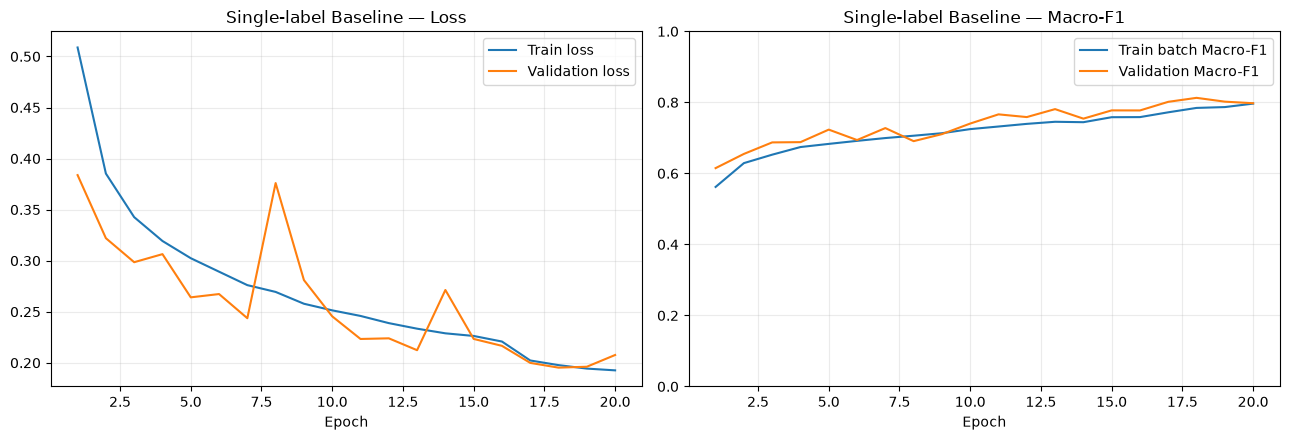

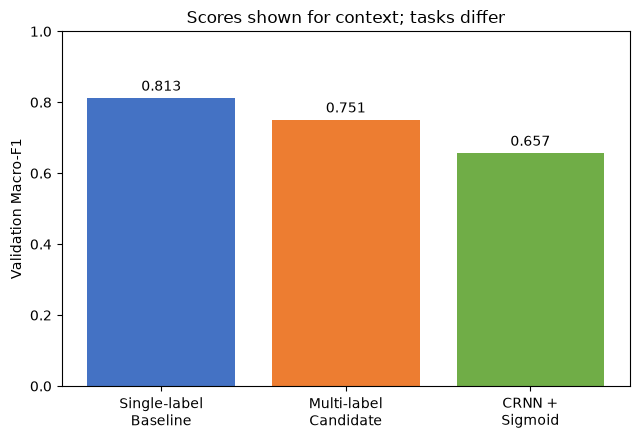

In [ ]:
comparison = pd.DataFrame([
    {'Model':'Single-label Baseline','Task':'เลือก 1 คลาส','Validation Macro-F1':single_metrics['validation_macro_f1'],
     'Validation Accuracy':single_metrics['validation_accuracy'],'Micro-F1':np.nan,'Exact Match':single_metrics['validation_exact_match'],'Hamming Loss':np.nan},
    {'Model':'Multi-label Candidate','Task':'CNN 16–128 + Sigmoid','Validation Macro-F1':multi_metrics['validation_macro_f1'],
     'Validation Accuracy':np.nan,'Micro-F1':multi_metrics['validation_micro_f1'],'Exact Match':multi_metrics['validation_exact_match'],'Hamming Loss':multi_metrics['validation_hamming_loss']},
    {'Model':'CRNN + Sigmoid','Task':'CNN (16–128) + BiGRU + Sigmoid','Validation Macro-F1':crnn_metrics['validation_macro_f1'],
     'Validation Accuracy':np.nan,'Micro-F1':crnn_metrics['validation_micro_f1'],'Exact Match':crnn_metrics['validation_exact_match'],'Hamming Loss':crnn_metrics['validation_hamming_loss']},
])
display(comparison.style.format({c:'{:.4f}' for c in comparison.columns if c not in ['Model','Task']}))

# Training curves: batch Macro-F1 is measured from augmented training batches during optimization.
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].plot(history_df.epoch,history_df.train_loss,label='Train loss')
axes[0].plot(history_df.epoch,history_df.val_loss,label='Validation loss')
axes[0].set_title('Single-label Baseline — Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].plot(history_df.epoch,history_df.train_macro_f1,label='Train batch Macro-F1')
axes[1].plot(history_df.epoch,history_df.val_macro_f1,label='Validation Macro-F1')
axes[1].set_ylim(0,1); axes[1].set_title('Single-label Baseline — Macro-F1'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=.25)
fig.tight_layout()
training_curves_path=ASSET_DIR/'rakforest_singlelabel_training_curves.png'
fig.savefig(training_curves_path,dpi=220,bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(6.5,4.5))
bars=ax.bar(['Single-label\nBaseline','Multi-label\nCandidate','CRNN +\nSigmoid'],[single_metrics['validation_macro_f1'],multi_metrics['validation_macro_f1'],crnn_metrics['validation_macro_f1']],color=['#4472C4','#ED7D31','#70AD47'])
ax.set_ylim(0,1); ax.set_ylabel('Validation Macro-F1'); ax.set_title('Scores shown for context; tasks differ')
for bar,value in zip(bars,[single_metrics['validation_macro_f1'],multi_metrics['validation_macro_f1'],crnn_metrics['validation_macro_f1']]):
    ax.text(bar.get_x()+bar.get_width()/2,value+.02,f'{value:.3f}',ha='center')
fig.tight_layout()
comparison_image_path=ASSET_DIR/'rakforest_three_model_validation.png'
fig.savefig(comparison_image_path,dpi=220,bbox_inches='tight'); plt.show()


In [ ]:
# เปรียบเทียบคำตอบของโมเดลบนคลิป Validation เดียวกัน (ภาพนี้ใช้เพื่ออธิบายพฤติกรรม ไม่ใช่ผลแทนทั้งชุด)
example_index = 0
true_labels = val_df.iloc[example_index].target_labels_list
single_label = CLASS_NAMES[int(single_pred[example_index])]
multi_labels = [CLASS_NAMES[i] for i in np.where(multi_pred[example_index]==1)[0]]
crnn_labels = [CLASS_NAMES[i] for i in np.where(crnn_pred[example_index]==1)[0]]
if not multi_labels: multi_labels=['(ไม่มีคลาสผ่าน threshold 0.5)']
print('Ground-truth labels:', true_labels)
print('Single-label prediction:', single_label)
print('Multi-label Candidate prediction:', multi_labels)
print('CRNN + Sigmoid prediction:', crnn_labels or ['(none passed threshold)'])

result = {
  'validation_rows':len(val_df),
  'single_label':single_metrics,
  'multi_label_candidate':multi_metrics,
  'crnn_sigmoid':crnn_metrics,
  'crnn_checkpoint':str(crnn_path.relative_to(PROJECT_ROOT)),
  'candidate_checkpoint':str(candidate_path.relative_to(PROJECT_ROOT)),
  'single_checkpoint':str(single_checkpoint_path.relative_to(PROJECT_ROOT)),
  'note':'Validation only. Different target/output tasks; do not interpret score difference as a direct ranking.'
}
result_path=REPORT_DIR/'single_multi_crnn_validation_comparison.json'
result_path.write_text(json.dumps(result,indent=2,ensure_ascii=False))
print('Saved comparison:',result_path)
print('Saved presentation images:',mel_image_path, comparison_image_path)


Ground-truth labels: ['vehicle']
Single-label prediction: vehicle
Multi-label Candidate prediction: ['fire', 'vehicle']
CRNN + Sigmoid prediction: ['vehicle']
Saved comparison: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/single_multi_crnn_validation_comparison.json
Saved presentation images: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/presentation_assets/rakforest_validation_log_mel.png /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/presentation_assets/rakforest_three_model_validation.png


## 8. Controlled demo: ทดลองเสียงสองเหตุการณ์ในคลิปเดียว

นำคลิป Validation สองคลาสที่มีป้ายแยกกันมาผสม แล้วส่งเสียงเดียวกันเข้า Baseline, Candidate และ CRNN + Sigmoid เพื่อดูพฤติกรรมการตอบ ใช้ threshold 0.5 ตาม config ของ Candidate

> นี่เป็น controlled demonstration จากเสียงผสมที่สร้างขึ้น ไม่ใช่ผลประเมินบนเสียงผสมจริง และห้ามนำมาแทน Validation/Test metrics


Known source labels in constructed mix: ['chainsaw', 'weather']
Single-label Baseline output (one class): other
Multi-label Candidate outputs (threshold=0.5): ['other']
CRNN + Sigmoid outputs (threshold=0.5): ['other']


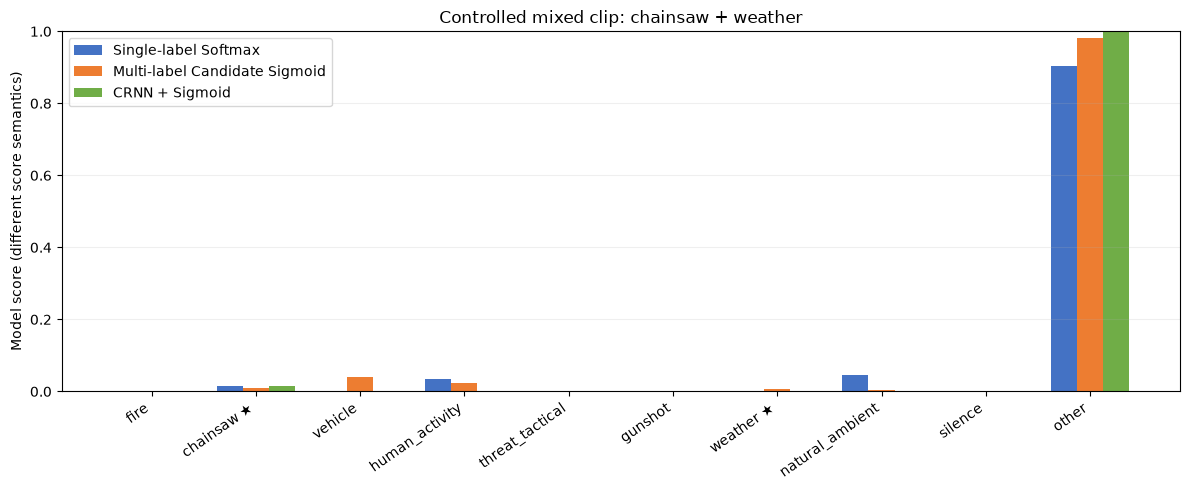

★ marks the two source labels used to construct this mixed clip.
Saved demo figure: /Users/guidegiegg/งาน/โปรเจคเล็กๆ/RakForest---AI-Powered-Abnormal-Forest-Sound-Detection/reports/presentation_assets/rakforest_controlled_mix_three_model_response.png


In [ ]:
# Choose two different validation recordings with known single source labels.
def choose_validation_clip(label, exclude_group=None):
    candidates = val_df[val_df.target_label.eq(label)]
    if exclude_group is not None: candidates = candidates[candidates.group_key.astype(str).ne(str(exclude_group))]
    if candidates.empty: raise ValueError(f'No validation clip found for {label}')
    return candidates.iloc[0]

source_a = choose_validation_clip('chainsaw')
source_b = choose_validation_clip('weather', exclude_group=source_a.group_key)
wave_a = load_wave(source_a.processed_file)
wave_b = load_wave(source_b.processed_file)

def mix_for_demo(primary, secondary, secondary_snr_db=0.0):
    rms_a = float(np.sqrt(np.mean(primary**2)))
    rms_b = float(np.sqrt(np.mean(secondary**2)))
    if rms_a < 1e-7 or rms_b < 1e-7: raise ValueError('A selected clip is silent')
    gain = (rms_a/rms_b) * (10**(secondary_snr_db/20))
    mixed = primary + gain*secondary
    peak = float(np.max(np.abs(mixed)))
    if peak > .99: mixed *= .99/peak
    return mixed.astype(np.float32)

mixed_audio = mix_for_demo(wave_a, wave_b, secondary_snr_db=0.0)
mixed_feature, mixed_db = to_logmel(mixed_audio)
known_mixed_labels = [source_a.target_label, source_b.target_label]

with torch.no_grad():
    x = torch.from_numpy(mixed_feature).unsqueeze(0).unsqueeze(0).to(DEVICE)
    single_response = torch.softmax(single_model(x), dim=1)[0].cpu().numpy()
    candidate_response = torch.sigmoid(candidate_model(x))[0].cpu().numpy()
    crnn_response = torch.sigmoid(crnn_model(x))[0].cpu().numpy()

single_response_label = CLASS_NAMES[int(single_response.argmax())]
candidate_response_labels = [CLASS_NAMES[i] for i,p in enumerate(candidate_response) if p >= THRESHOLD]
crnn_response_labels = [CLASS_NAMES[i] for i,p in enumerate(crnn_response) if p >= THRESHOLD]
print('Known source labels in constructed mix:', known_mixed_labels)
print('Single-label Baseline output (one class):', single_response_label)
print(f'Multi-label Candidate outputs (threshold={THRESHOLD}):', candidate_response_labels or ['(none passed threshold)'])
print(f'CRNN + Sigmoid outputs (threshold={THRESHOLD}):', crnn_response_labels or ['(none passed threshold)'])
display(Audio(mixed_audio, rate=SAMPLE_RATE))

# Visualize model outputs. Softmax and sigmoid scores have different meanings; bars are not directly comparable.
plot_labels = [f'{name} ★' if name in known_mixed_labels else name for name in CLASS_NAMES]
xx = np.arange(len(CLASS_NAMES)); width=.25
fig,ax=plt.subplots(figsize=(12,5))
ax.bar(xx-width, single_response, width, label='Single-label Softmax', color='#4472C4')
ax.bar(xx, candidate_response, width, label='Multi-label Candidate Sigmoid', color='#ED7D31')
ax.bar(xx+width, crnn_response, width, label='CRNN + Sigmoid', color='#70AD47')
ax.set_xticks(xx, plot_labels, rotation=35, ha='right')
ax.set_ylim(0,1); ax.set_ylabel('Model score (different score semantics)')
ax.set_title(f'Controlled mixed clip: {known_mixed_labels[0]} + {known_mixed_labels[1]}')
ax.legend(); ax.grid(axis='y',alpha=.2); fig.tight_layout()
mix_demo_image_path=ASSET_DIR/'rakforest_controlled_mix_three_model_response.png'
fig.savefig(mix_demo_image_path,dpi=220,bbox_inches='tight')
plt.show()
print('★ marks the two source labels used to construct this mixed clip.')
print('Saved demo figure:',mix_demo_image_path)


## 9. ข้อจำกัดในการพูดถึงผล

- Candidate Model คือ CNN 16–128 + Sigmoid จาก `03_train_model.ipynb`; CRNN + Sigmoid ใช้ CNN (16–128) + BiGRU (hidden size 64) และฝึกแยกใน `09_train_crnn_sigmoid.ipynb`
- Notebook ฝึก Baseline ใหม่เพื่อแก้ความไม่สอดคล้องของไฟล์ baseline เดิม
- Manifest ปัจจุบันมี ground truth หนึ่งคลาสต่อคลิป แม้ Candidate จะออกแบบให้ตอบได้หลายคลาสและใช้ waveform mixing ระหว่างฝึก จึงยังไม่มีตัวอย่าง Validation/Test ที่ยืนยันเสียงหลายเหตุการณ์พร้อมกัน
- ตารางและกราฟเป็นผล Validation; อย่าเรียกเป็นผล Test และอย่าตีความคะแนนต่างกันเป็นการจัดอันดับตรง ๆ
- Training Macro-F1 ใช้ predictions จาก batch ที่ผ่าน augmentation ระหว่างฝึก ใช้ดูแนวโน้ม ไม่ใช่ค่า eval แยกอีก pass
- Controlled demo เป็นเสียงผสมสังเคราะห์ ใช้แสดงรูปแบบคำตอบเท่านั้น ไม่ใช่หลักฐานประสิทธิภาพกับเสียงผสมจริง
- ไฟล์ภาพสำหรับ Canva อยู่ใน `reports/presentation_assets/rakforest_validation_log_mel.png` และ `reports/presentation_assets/rakforest_three_model_validation.png`
